In [ ]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score

In [26]:
from sklearn.feature_extraction import DictVectorizer

In [35]:
from sklearn.linear_model import LogisticRegression

In [3]:
#loading data
df=pd.read_csv('https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/course_lead_scoring_2026.csv')

In [5]:
#checking whether there are missing values in the dataset
df.isnull().sum()

lead_source                 148
industry                    240
employment_status           194
location                    208
annual_income               369
number_of_courses_viewed      0
interaction_count             0
lead_score                   35
converted                     0
dtype: int64

In [8]:
#checking categorical and numerical columns
df.nunique()

lead_source                    5
industry                       6
employment_status              4
location                       5
annual_income               4313
number_of_courses_viewed       7
interaction_count             14
lead_score                    99
converted                      2
dtype: int64

In [13]:
categorical=['lead_source','industry','employment_status','location']
numerical=['annual_income','lead_score','number_of_courses_viewed','interaction_count']

In [11]:
#filling missing values in categorical columns with NA
for col in categorical:
    df[col]=df[col].fillna('NA')

In [14]:
#filling missing values in numerical columns with 0.0
for col in numerical:
    df[col]=df[col].fillna(0.0)

In [19]:
#splitting data
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(
    df_full_train, test_size=0.25, random_state=1
)

In [23]:
#treatinf numerical variables as predictors and calculating the AUC score for each of them
score=[]
for col in numerical:
    auc=roc_auc_score(df_train['converted'],df_train[col])
    if auc<0.5:
        auc=roc_auc_score(df_train['converted'],-df_train[col])
    score.append((col,auc))

In [25]:
sorted(score, key=lambda x: x[1], reverse=True)

[('lead_score', np.float64(0.7882254810906102)),
 ('interaction_count', np.float64(0.7649203047563227)),
 ('number_of_courses_viewed', np.float64(0.7229894623989618)),
 ('annual_income', np.float64(0.6081977776250831))]

In [27]:
df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)

In [28]:
y_train = df_train.converted.values
y_val = df_val.converted.values
y_test = df_test.converted.values

del df_train['converted']
del df_val['converted']
del df_test['converted']

In [30]:
#one hot encoding categorical variable using DictVectorizer
dv=DictVectorizer(sparse=False)
train_dict=df_train[categorical+numerical].to_dict(orient='records')
X_train=dv.fit_transform(train_dict)

val_dict=df_val[categorical+numerical].to_dict(orient='records')
X_val=dv.transform(val_dict)


In [36]:
#training the logistic regression model
model=LogisticRegression(solver='liblinear',C=1.0,max_iter=1000)

In [37]:
#fitting the model
model.fit(X_train,y_train)

LogisticRegression(max_iter=1000, solver='liblinear')

In [55]:
#auc score on validation set
y_pred=model.predict_proba(X_val)[:,1]
auc=roc_auc_score(y_val,y_pred)

In [56]:
print(f'auc score on validation set: {auc:.3f}')

auc score on validation set: 0.732


In [ ]:
#threshold range from 0.0 to 1.0 with step size of 0.01
t=np.arange(0.0,1.01,0.01)

In [57]:
y_pred

array([0.54472295, 0.79005207, 0.50977908, 0.52913949, 0.82072027,
       0.54245999, 0.50178716, 0.54698397, 0.82553299, 0.40583753,
       0.91301567, 0.33581825, 0.30789882, 0.42704802, 0.62192289,
       0.53665458, 0.41931936, 0.84087345, 0.79969125, 0.61790114,
       0.61625181, 0.6805993 , 0.85605897, 0.8078487 , 0.62046017,
       0.45970721, 0.54556723, 0.41221392, 0.72714023, 0.46812079,
       0.7722219 , 0.79043883, 0.61433884, 0.78549759, 0.49753425,
       0.6607729 , 0.69804762, 0.76896543, 0.65657501, 0.6412791 ,
       0.66509115, 0.57942825, 0.67830946, 0.61186113, 0.86890227,
       0.4146967 , 0.84130129, 0.74229365, 0.68028539, 0.7189143 ,
       0.86417929, 0.64043374, 0.5424699 , 0.70225152, 0.27894903,
       0.70826493, 0.62310717, 0.4778177 , 0.37914031, 0.69936034,
       0.52032869, 0.69977698, 0.75148939, 0.58087503, 0.47001802,
       0.56863491, 0.91297185, 0.79972028, 0.82206546, 0.36140197,
       0.66132404, 0.52330064, 0.79295471, 0.72068083, 0.71234

In [ ]:
from sklearn.metrics import precision_score, recall_score


In [70]:
from sklearn.metrics import f1_score

In [71]:
#calculatinf precision, recall  for each threshold
precision=[]
recall=[]
f1_score_list=[]
for th in t:
    y_pred_labels=[1 if p>=th else 0 for p in y_pred]
    p=precision_score(y_val, y_pred_labels)
    r=recall_score(y_val, y_pred_labels)
    f=f1_score(y_val, y_pred_labels)
    precision.append(p)
    recall.append(r)
    f1_score_list.append(f)

c:\Users\lenovo\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
c:\Users\lenovo\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
c:\Users\lenovo\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
c:\Users\lenovo\anaconda3\Lib\site-packages\sklearn\metrics\_

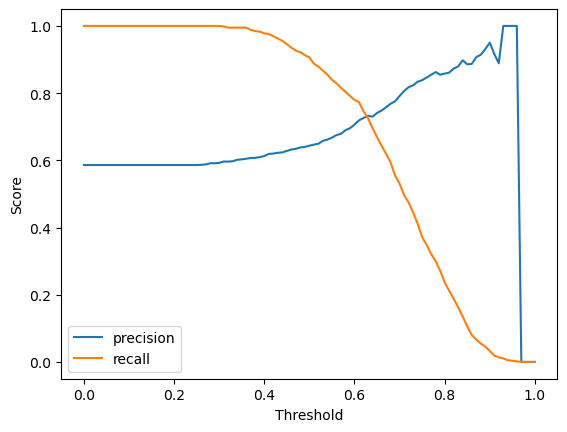

In [72]:
#plotting precision and recall against threshold
import matplotlib.pyplot as plt
plt.plot(t, precision, label='precision')
plt.plot(t, recall, label='recall')
plt.xlabel('Threshold')
plt.ylabel('Score')
plt.legend()
plt.show()

In [69]:
precision = np.array(precision)
recall = np.array(recall)

# keep only thresholds where not both metrics are zero
mask = ~((precision == 0) & (recall == 0))

diff = np.abs(precision[mask] - recall[mask])
best = np.argmin(diff)

print(t[mask][best])

0.63


In [73]:
#finding threshold where f1 score is maximum
f1_score_list = np.array(f1_score_list)
best_f1_threshold = t[np.argmax(f1_score_list)]

In [74]:
best_f1_threshold

np.float64(0.41000000000000003)

In [76]:
from sklearn.model_selection import KFold, cross_val_score

In [77]:
#making cross validation with 5 folds
kf = KFold(n_splits=5, shuffle=True, random_state=1)

In [78]:
df_full_train.head()

,lead_source,industry,employment_status,location,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
1233,paid_ads,technology,student,europe,38757.0,0,0,0.15,0
1056,paid_ads,healthcare,self_employed,north_america,56516.0,2,6,0.59,1
1686,paid_ads,retail,employed,NA,54963.0,1,0,0.13,0
187,social_media,retail,self_employed,NA,26237.0,1,5,0.46,0
3840,organic_search,retail,student,north_america,21992.0,3,6,0.70,1


In [79]:
#iterating through each fold and calculating the AUC score for each fold
auc_scores=[]
for train_index, val_index in kf.split(df_full_train):
    df_train = df_full_train.iloc[train_index]
    df_val = df_full_train.iloc[val_index]

    y_train = df_train.converted.values
    y_val = df_val.converted.values

    del df_train['converted']
    del df_val['converted']

    train_dict = df_train[categorical + numerical].to_dict(orient='records')
    X_train = dv.fit_transform(train_dict)

    val_dict = df_val[categorical + numerical].to_dict(orient='records')
    X_val = dv.transform(val_dict)

    model.fit(X_train, y_train)

    y_pred = model.predict_proba(X_val)[:, 1]
    auc = roc_auc_score(y_val, y_pred)
    auc_scores.append(auc)

In [81]:
#calculating standard deviation of AUC scores
std_auc = np.std(auc_scores)

In [83]:
round(std_auc, 3)

np.float64(0.007)

In [84]:
df_full_train

,lead_source,industry,employment_status,location,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
1233,paid_ads,technology,student,europe,38757.0,0,0,0.15,0
1056,paid_ads,healthcare,self_employed,north_america,56516.0,2,6,0.59,1
1686,paid_ads,retail,employed,NA,54963.0,1,0,0.13,0
187,social_media,retail,self_employed,NA,26237.0,1,5,0.46,0
3840,organic_search,retail,student,north_america,21992.0,3,6,0.70,1
...,...,...,...,...,...,...,...,...,...
2895,paid_ads,manufacturing,NA,north_america,66121.0,1,1,0.20,0
2763,paid_ads,manufacturing,employed,north_america,60720.0,4,6,0.69,1
905,NA,manufacturing,NA,NA,49820.0,2,3,0.44,0
3980,organic_search,manufacturing,self_employed,north_america,52228.0,3,5,0.50,0


In [89]:
#using different values of C to find the best regularization parameter
c=[0.000001, 0.001, 1]
mean_roc=[]
std_roc=[]
for c in c:
    model=LogisticRegression(solver='liblinear',C=c,max_iter=1000)
    auc_scores=[]
    for train_index,val_index in kf.split(df_full_train):
        
        df_train=df_full_train.iloc[train_index]
        df_val=df_full_train.iloc[val_index]

        y_train=df_train.converted.values
        y_val=df_val.converted.values

        del df_train['converted']
        del df_val['converted']

        train_dict=df_train[categorical+numerical].to_dict(orient='records')
        X_train=dv.fit_transform(train_dict)

        val_dict=df_val[categorical+numerical].to_dict(orient='records')
        X_val=dv.transform(val_dict)

        model.fit(X_train,y_train)
        y_pred=model.predict_proba(X_val)[:,1]
        auc=roc_auc_score(y_val,y_pred)
        auc_scores.append(auc)
    mean_roc.append(np.mean(auc_scores))
    std_roc.append(np.std(auc_scores))


        


In [90]:
mean_roc

[np.float64(0.6167342250714795),
 np.float64(0.7491721776030379),
 np.float64(0.7317269710972524)]

In [88]:
std_roc

[np.float64(0.007042707627282115),
 np.float64(0.0068710258529644545),
 np.float64(0.006853233151022138),
 np.float64(0.006857974774749918)]